Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


Load the compost dataset

In [2]:
df = pd.read_csv("/content/Compost Data.csv")
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
display(df.head())

Dataset loaded successfully!
Number of rows: 452
Number of columns: 14


,Day,Temperature,MC(%),pH,C/N Ratio,Ammonia(mg/kg),Nitrate(mg/kg),TN(%),TOC(%),EC(ms/cm),OM(%),T Value,GI(%),Score
0,0,35.463,60.0000,5.7345,26.7755,2515.0,325.49,1.80632,48.365121,1.7846,83.381469,1.000000,32.8821,28.042095
1,3,41.866,56.8814,7.1327,23.0494,3449.1,302.42,1.92498,44.369634,2.4366,76.493249,0.860839,39.4615,36.185328
2,6,59.134,53.0847,7.9646,20.4697,5197.6,243.40,1.83675,37.597721,3.0118,64.818472,0.764494,30.5469,37.074037
3,9,53.119,49.4237,8.1770,18.7500,1940.1,203.99,1.78550,33.478125,3.1566,57.716287,0.700267,63.1219,51.246933
4,12,38.955,45.2203,8.0177,17.0303,814.4,200.52,1.91893,32.679954,3.5596,56.340240,0.636040,79.4691,59.698282


In [3]:
print("Dataset information:")
df.info()
print("\nColumn names:")
print(df.columns.tolist())
print("\nStatistical summary:")
display(df.describe().round(2))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Day             452 non-null    int64  
 1   Temperature     452 non-null    float64
 2   MC(%)           452 non-null    float64
 3   pH              452 non-null    float64
 4   C/N Ratio       452 non-null    float64
 5   Ammonia(mg/kg)  452 non-null    float64
 6   Nitrate(mg/kg)  452 non-null    float64
 7   TN(%)           452 non-null    float64
 8   TOC(%)          452 non-null    float64
 9   EC(ms/cm)       452 non-null    float64
 10  OM(%)           452 non-null    float64
 11  T Value         452 non-null    float64
 12  GI(%)           452 non-null    float64
 13  Score           452 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 49.6 KB

Column names:
['Day', 'Temperature', 'MC(%)', 'pH', 'C/N Ratio', 'Ammonia(mg/kg)', 'Nitrate(mg/kg)', 

,Day,Temperature,MC(%),pH,C/N Ratio,Ammonia(mg/kg),Nitrate(mg/kg),TN(%),TOC(%),EC(ms/cm),OM(%),T Value,GI(%),Score
count,452.00,452.00,452.00,452.00,452.00,452.00,452.00,452.00,452.00,452.00,452.00,452.00,452.00,452.00
mean,14.03,34.17,49.11,7.39,19.70,1268.81,460.85,1.75,31.46,2.74,64.76,0.76,69.50,50.91
std,12.15,14.16,12.28,0.85,6.57,1884.64,840.50,0.76,11.56,1.94,13.53,0.21,29.70,17.49
min,0.00,9.52,11.01,4.28,4.63,3.70,0.00,0.16,1.13,0.69,20.57,0.15,0.58,0.00
25%,5.00,23.38,42.75,6.85,14.70,403.38,34.89,1.35,28.30,1.36,54.02,0.61,46.78,36.00
50%,12.00,30.46,48.58,7.39,18.43,710.44,247.89,1.84,32.67,2.00,62.83,0.74,70.08,51.43
75%,21.00,45.06,57.71,8.04,23.52,1131.72,536.40,2.21,37.66,3.45,76.50,0.97,89.64,64.50
max,120.00,68.80,79.22,9.37,39.72,13407.00,6048.23,4.07,58.83,11.14,97.07,1.56,167.36,100.00


Check missing values and duplicates

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
Day               0
Temperature       0
MC(%)             0
pH                0
C/N Ratio         0
Ammonia(mg/kg)    0
Nitrate(mg/kg)    0
TN(%)             0
TOC(%)            0
EC(ms/cm)         0
OM(%)             0
T Value           0
GI(%)             0
Score             0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


Exploratory Data Analysis (EDA)

Coorelation Heatmap

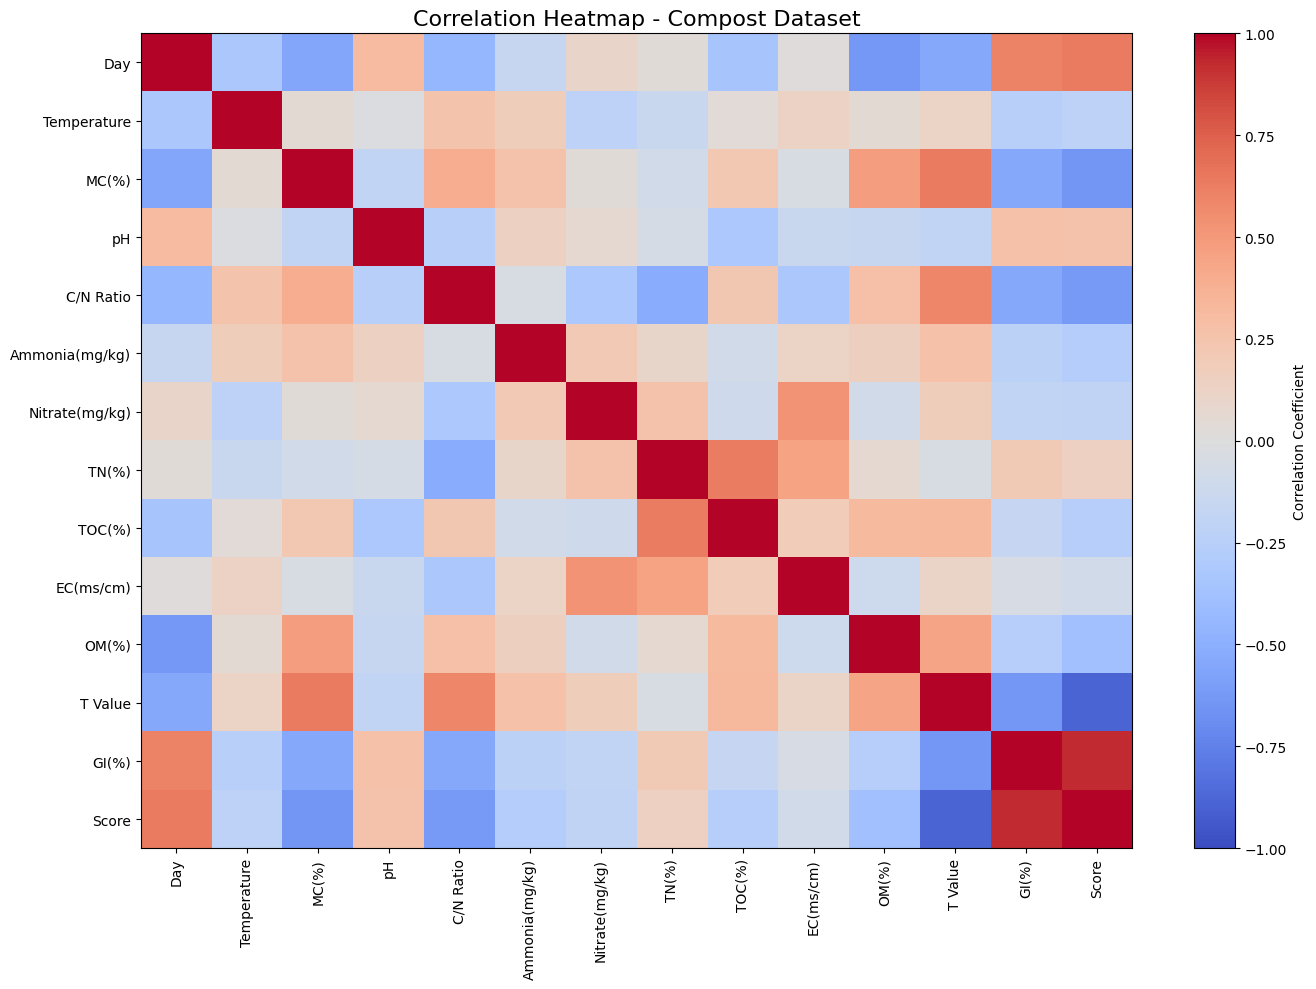

In [5]:
import matplotlib.pyplot as plt
import numpy as np
# Calculate correlation between numerical columns
correlation = df.corr(numeric_only=True)
plt.figure(figsize=(14, 10))
plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)
plt.colorbar(label="Correlation Coefficient")
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)
plt.title("Correlation Heatmap - Compost Dataset", fontsize=16)
plt.tight_layout()
plt.show()

In [6]:
print("Score statistics:")
print(df["Score"].describe())

print("\nMinimum Score:", df["Score"].min())
print("Maximum Score:", df["Score"].max())
print("Average Score:", df["Score"].mean())

Score statistics:
count    4.520000e+02
mean     5.091066e+01
std      1.748948e+01
min      2.020000e-10
25%      3.600214e+01
50%      5.142949e+01
75%      6.449568e+01
max      1.000022e+02
Name: Score, dtype: float64

Minimum Score: 2.02e-10
Maximum Score: 100.0022276
Average Score: 50.910662502794686


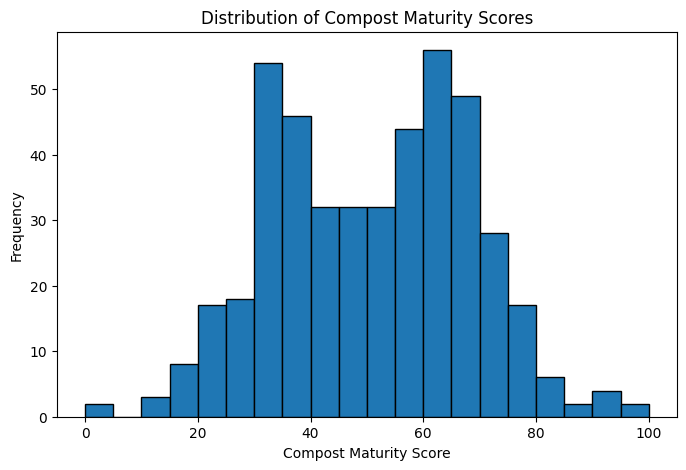

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(df["Score"], bins=20, edgecolor="black")
plt.xlabel("Compost Maturity Score")
plt.ylabel("Frequency")
plt.title("Distribution of Compost Maturity Scores")
plt.show()

Maturity score against composting day

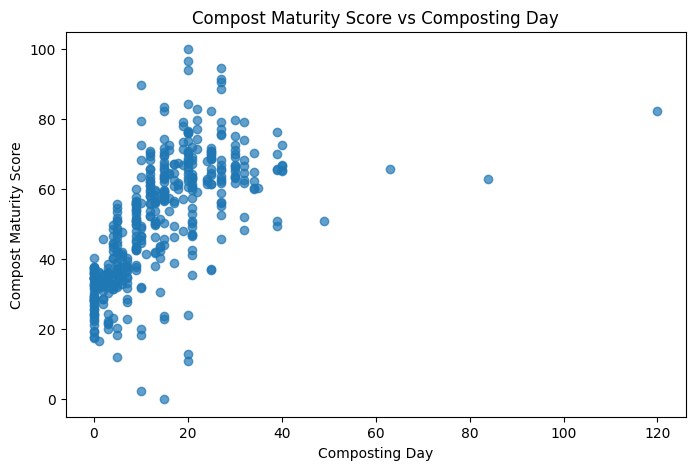

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Day"], df["Score"], alpha=0.7)
plt.xlabel("Composting Day")
plt.ylabel("Compost Maturity Score")
plt.title("Compost Maturity Score vs Composting Day")

plt.show()

Feature Selection and Data Splitting

In [9]:
features = [
    "Day",
    "Temperature",
    "MC(%)",
    "pH",
    "Ammonia(mg/kg)",
    "Nitrate(mg/kg)",
    "TN(%)",
    "TOC(%)",
    "EC(ms/cm)",
    "OM(%)"
]
target = "Score"
X = df[features]
y = df[target]
print("Input features:")
print(features)
print("\nX shape:", X.shape)
print("y shape:", y.shape)

Input features:
['Day', 'Temperature', 'MC(%)', 'pH', 'Ammonia(mg/kg)', 'Nitrate(mg/kg)', 'TN(%)', 'TOC(%)', 'EC(ms/cm)', 'OM(%)']

X shape: (452, 10)
y shape: (452,)


Train and Compare Five Models

In [10]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),
    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR())
    ])
}
print("Five regression models defined successfully!")

Five regression models defined successfully!


Train the models and evaluate their predictions

In [11]:
from sklearn.model_selection import train_test_split

# Select input features
features = [
    "Day", "Temperature", "MC(%)", "pH",
    "Ammonia(mg/kg)", "Nitrate(mg/kg)", "TN(%)",
    "TOC(%)", "EC(ms/cm)", "OM(%)"
]

# Input data and target
X = df[features]
y = df["Score"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 361
Testing samples: 91


In [12]:
results = []
trained_models = {}

for name, model in models.items():
    # Train model
    model.fit(X_train, y_train)
    # Predict test values
    predictions = model.predict(X_test)
    # Calculate metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )
    r2 = r2_score(y_test, predictions)

    # Cross-validation using training data only
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Test R2": r2,
        "CV Mean R2": cv_scores.mean(),
        "CV Std": cv_scores.std()
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="CV Mean R2",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,MAE,RMSE,Test R2,CV Mean R2,CV Std
0,Random Forest,4.4297,6.8375,0.8300,0.8063,0.0136
1,Gradient Boosting,4.8368,6.8422,0.8297,0.7942,0.0383
2,Linear Regression,6.2932,8.3874,0.7442,0.6725,0.0868
3,Decision Tree,6.9049,10.1027,0.6288,0.6244,0.1004
4,SVR,6.9128,10.0896,0.6298,0.5851,0.0829


Hyperparameter Tuning

In [13]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV R2:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV R2: 0.807


Evaluate the tuned model

In [14]:
original_rf = trained_models["Random Forest"]
tuned_rf = grid_search.best_estimator_

original_predictions = original_rf.predict(X_test)
tuned_predictions = tuned_rf.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "MAE": mean_absolute_error(
            y_test, original_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, original_predictions)
        ),
        "R2": r2_score(y_test, original_predictions)
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": mean_absolute_error(
            y_test, tuned_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, tuned_predictions)
        ),
        "R2": r2_score(y_test, tuned_predictions)
    }
])

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Original Random Forest,4.4297,6.8375,0.8300
1,Tuned Random Forest,4.4537,6.7992,0.8319


Final Model Evaluation

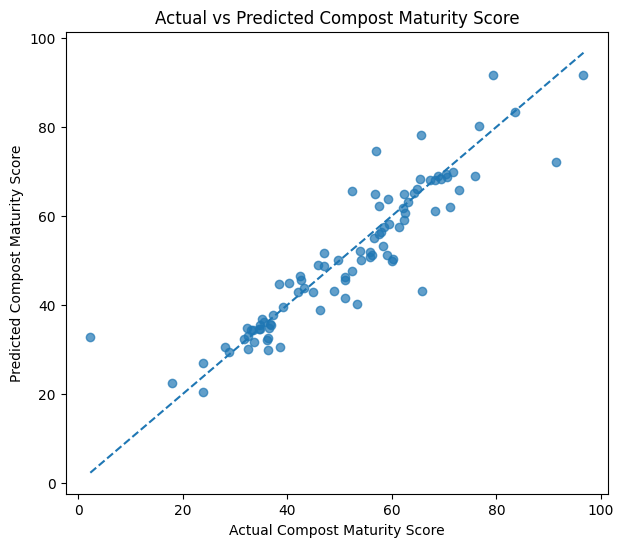

In [15]:
final_candidate = grid_search.best_estimator_

y_pred = final_candidate.predict(X_test)

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Compost Maturity Score")
plt.ylabel("Predicted Compost Maturity Score")
plt.title("Actual vs Predicted Compost Maturity Score")

plt.show()

In [16]:
final_mae = mean_absolute_error(y_test, y_pred)

final_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

final_r2 = r2_score(y_test, y_pred)

print("Final Candidate: Tuned Random Forest")
print("------------------------------------")
print("MAE:", round(final_mae, 4))
print("RMSE:", round(final_rmse, 4))
print("R2 Score:", round(final_r2, 4))

Final Candidate: Tuned Random Forest
------------------------------------
MAE: 4.4537
RMSE: 6.7992
R2 Score: 0.8319


In [17]:
final_model = grid_search.best_estimator_

joblib.dump(
    final_model,
    "/content/compost_maturity_model.pkl"
)

joblib.dump(
    features,
    "/content/compost_feature_names.pkl"
)

print("Final model saved successfully!")
print("Feature names saved successfully!")

Final model saved successfully!
Feature names saved successfully!


In [18]:
from google.colab import files

files.download("/content/compost_maturity_model.pkl")
files.download("/content/compost_feature_names.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Build the Gradio Application

In [22]:

import gradio as gr
import pandas as pd
import joblib

# Load the trained model and feature names
model = joblib.load("compost_maturity_model.pkl")
feature_names = joblib.load("compost_feature_names.pkl")


def predict_maturity(
    day,
    temperature,
    moisture,
    ph,
    ammonia,
    nitrate,
    total_nitrogen,
    total_organic_carbon,
    electrical_conductivity,
    organic_matter
):
    input_data = pd.DataFrame([{
        "Day": day,
        "Temperature": temperature,
        "MC(%)": moisture,
        "pH": ph,
        "Ammonia(mg/kg)": ammonia,
        "Nitrate(mg/kg)": nitrate,
        "TN(%)": total_nitrogen,
        "TOC(%)": total_organic_carbon,
        "EC(ms/cm)": electrical_conductivity,
        "OM(%)": organic_matter
    }])

    # Match the feature order used during model training
    input_data = input_data[feature_names]

    prediction = model.predict(input_data)[0]

    return round(float(prediction), 2)


with gr.Blocks(title="Compost Maturity Prediction System") as demo:

    gr.Markdown("# 🌱 Compost Maturity Prediction System")

    gr.Markdown(
        "Enter compost measurements to estimate the maturity score "
        "using a trained Random Forest regression model."
    )

    gr.Markdown("### Composting Conditions")

    with gr.Row():
        day = gr.Number(label="Composting Day", value=12)
        temperature = gr.Number(label="Temperature (°C)", value=38)
        moisture = gr.Number(label="Moisture Content (%)", value=45)

    gr.Markdown("### Chemical Properties")

    with gr.Row():
        ph = gr.Number(label="pH", value=8)
        ammonia = gr.Number(label="Ammonia (mg/kg)", value=1500)
        nitrate = gr.Number(label="Nitrate (mg/kg)", value=200)

    with gr.Row():
        total_nitrogen = gr.Number(label="Total Nitrogen (%)", value=1.9)
        total_organic_carbon = gr.Number(
            label="Total Organic Carbon (%)", value=30
        )

    with gr.Row():
        electrical_conductivity = gr.Number(
            label="Electrical Conductivity (ms/cm)", value=3
        )
        organic_matter = gr.Number(label="Organic Matter (%)", value=50)

    predict_button = gr.Button(
        "Predict Maturity Score", variant="primary"
    )

    output = gr.Number(label="Predicted Compost Maturity Score")

    predict_button.click(
        fn=predict_maturity,
        inputs=[
            day, temperature, moisture, ph, ammonia, nitrate,
            total_nitrogen, total_organic_carbon,
            electrical_conductivity, organic_matter
        ],
        outputs=output
    )

    gr.Markdown(
        "Note: This is a model-based estimate, not a laboratory "
        "certification of compost maturity."
    )

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://673260da233b90d39c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [23]:
import gradio
import sklearn
import pandas
import numpy
import joblib

print("gradio:", gradio.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("joblib:", joblib.__version__)

gradio: 6.31.0
scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.4.6
joblib: 1.6.0


In [25]:
%%writefile requirements.txt

gradio==6.31.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0

Overwriting requirements.txt
